# Clustering Model for Divvy Ridership

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### Load Data and Add a Weekend Column

In [73]:
df = pd.read_csv("daily_ridership_weather_2025.csv")

# Tell Python to read the 'date' column as actual calendar dates
df["date"] = pd.to_datetime(df["date"])

# Find the day of the week (0 = Monday, 1 = Tuesday, ... 5 = Saturday, 6 = Sunday)
df["day_of_week"] = df["date"].dt.day_of_week

# Create a column that is 1 if it is Saturday or Sunday, and 0 if it is a weekday
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# Show the first 5 rows just to make sure everything looks right
df[["date", "day_of_week", "is_weekend", "total_rides"]].head()

,date,day_of_week,is_weekend,total_rides
0,2025-01-01,2,0,3562
1,2025-01-02,3,0,4749
2,2025-01-03,4,0,4200
3,2025-01-04,5,1,3198
4,2025-01-05,6,1,2933


### Choose Columns for Clustering

In [74]:
columns_for_clustering = [
    "temperature_2m_mean (°F)",
    "precipitation_sum (inch)",
    "snowfall_sum (inch)",
    "wind_speed_10m_max (mp/h)",
    "is_weekend"
]

X = df[columns_for_clustering]

# Check the first 5 rows of our clustering inputs
X.head()

,temperature_2m_mean (°F),precipitation_sum (inch),snowfall_sum (inch),wind_speed_10m_max (mp/h),is_weekend
0,29.7,0.004,0.028,13.8,0
1,27.7,0.008,0.055,10.8,0
2,22.8,0.000,0.000,12.9,0
3,17.7,0.000,0.000,10.8,1
4,20.5,0.024,0.138,13.6,1


### Scale Numbers

In [75]:
scaler = StandardScaler()

# Scale our 5 columns so they are all measured on the same scale
X_scaled = scaler.fit_transform(X)

### Number of Clusters (k)

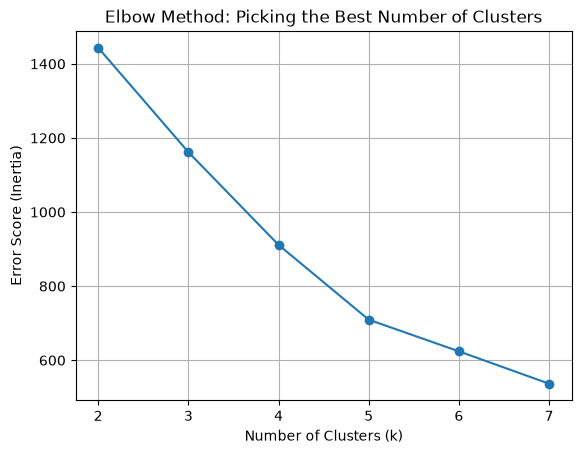

In [76]:
scores = []
k_options = [2, 3, 4, 5, 6, 7]

# Test each number of clusters one by one
for k in k_options:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    scores.append(model.inertia_)

# Draw the Elbow Chart
plt.plot(k_options, scores, marker="o")
plt.title("Elbow Method: Picking the Best Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Error Score (Inertia)")
plt.grid(True)
plt.show()

### Run K-Means and Compare Ridership Across Clusters

In [77]:
number_of_clusters = 5

# Run the final K-Means model and save the cluster labels (0, 1, 2, or 3) into our table
kmeans = KMeans(n_clusters=number_of_clusters, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

print("Number of days in each cluster:")
print(df["cluster"].value_counts())
print("\n" + "="*50 + "\n")

# Calculate the average weather and average ridership for each cluster
columns_to_compare = columns_for_clustering + ["total_rides", "member_rides", "casual_rides"]
cluster_summary = df.groupby("cluster")[columns_to_compare].mean().round(1)

# Sort from lowest average rides to highest average rides so it is easy to read
cluster_summary = cluster_summary.sort_values("total_rides")
cluster_summary

Number of days in each cluster:
cluster
3    134
0    109
1     96
4     19
2      7
Name: count, dtype: int64




,temperature_2m_mean (°F),precipitation_sum (inch),snowfall_sum (inch),wind_speed_10m_max (mp/h),is_weekend,total_rides,member_rides,casual_rides
cluster,,,,,,,,
2,28.5,0.4,2.2,14.9,0.6,3814.9,2929.0,885.9
0,35.0,0.0,0.1,13.9,0.0,8934.4,6819.9,2114.5
4,54.9,0.8,0.1,14.5,0.2,11709.1,8020.4,3688.7
1,52.0,0.0,0.0,10.8,1.0,15773.4,8282.2,7491.2
3,64.2,0.1,0.0,8.6,0.0,21012.5,13747.3,7265.2


### Clustering Interpretation & Trade-Offs

#### Clustering Choices and Justifications

- **Unit of Analysis:** Individual calendar days in 2025 (365 days total). We chose days instead of individual bike rides or stations because weather is measured daily and matches our merged daily table.
- **Variables Used:** Average daily temperature, total rain, total snow, max wind speed, and whether the day is a weekend. We chose these five clues because all of them are known ahead of time from a calendar and a weather forecast. We left out daily ride counts so there is no data leakage, and we used only average temperature (leaving out high and low temperatures) so temperature would not get counted three times.
- **Algorithm:** K-Means clustering. We scaled all numbers to the same range. K-Means automatically groups similar days together without us manually setting rules. Scaling the numbers first makes sure big numbers like temperature do not overpower small numbers like snow.
- **Number of Clusters (k = 5):** We picked 5 clusters based on our Elbow Method chart. The error score drops fast from 2 to 5 clusters and then bends and flattens out after 5, giving us five clear day types without splitting the year into too many small groups.


#### How Bike Rides Differ Across the 5 Groups
*(Ordered from slowest days to busiest days)*
- **Group 1 — Cluster 2 (7 days) | Freezing, Snowy Days:** Averages 28.5°F with 2.2 inches of snow and windy conditions (14.9 mph). This is by far the slowest group, averaging only 3,815 rides per day (mostly regular members, with almost no casual riders).
- **Group 2 — Cluster 0 (109 days) | Cold, Dry Workdays:** Averages 35.0°F with almost no rain or snow, and 100% of these days are Monday–Friday. Ridership more than doubles to 8,934 rides per day, driven mostly by weekday commuters (6,820 member rides vs. 2,115 casual rides).
- **Group 3 — Cluster 4 (19 days) | Rainy, Windy Days:** Mild temperatures (54.9°F), but heavy rain (0.8 inches) and gusty winds (14.5 mph) keep riders away. Averages 11,709 rides per day, showing that heavy rain cuts ridership nearly in half compared to dry warm days.
- **Group 4 — Cluster 1 (96 days) | Dry Weekends:** Pleasant temperatures (52.0°F) with zero rain or snow, and 100% of these days are Saturdays or Sundays. Averages 15,773 rides per day, with a massive jump in leisure riders (7,491 casual rides).
- **Group 5 — Cluster 3 (134 days) | Warm, Calm Workdays:** Warm weather (64.2°F), calm winds (8.6 mph), and Monday–Friday schedules. This is our busiest group, averaging 21,013 rides per day because both daily commuters (13,747 member rides) and casual riders (7,265 casual rides) are out at the same time.

#### What Grouping Days Helps With and What It Misses
* **What it helps with:** A manager can look at next week's weather forecast, match each upcoming day to one of these 5 groups, and quickly see whether to plan for a slow, average, or very busy day across Chicago. It also shows whether riders will be mostly commuters or casual weekend riders.
* **What it misses:** Because we grouped whole days instead of individual bike stations, this tells us how many total bikes will be used citywide, but not which specific stations or neighborhoods will run out of bikes.